# 03 · Customer Segmentation (RFM + K-Means)

Group customers by Recency, Frequency and Monetary value to give marketing actionable personas.

In [1]:
import sys, warnings, logging
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)

from src.config import *
from src.ingestion.etl import load_processed
D = load_processed()
tx, customers, products, inventory = D["transactions"], D["customers"], D["products"], D["inventory"]
daily = D["daily"]
print(f"Loaded {len(tx):,} clean transaction lines | {tx.customer_id.nunique():,} customers | "
      f"{tx.order_date.min().date()} -> {tx.order_date.max().date()}")

Loaded 54,339 clean transaction lines | 1,455 customers | 2024-01-01 -> 2025-12-31


## 1. RFM table

In [2]:
from src.segmentation.rfm import build_rfm, evaluate_k, fit_segmentation, predict_segments, segment_summary
rfm = build_rfm(tx)
rfm.describe().round(1)

,recency,frequency,monetary
count,1455.0,1455.0,1455.0
mean,128.6,37.3,4730.5
std,166.7,38.7,4970.4
min,1.0,1.0,8.7
25%,8.0,13.0,1575.6
50%,33.0,27.0,3390.6
75%,216.5,49.0,6280.7
max,731.0,462.0,58541.7


## 2. Choosing k
Frequency & monetary are right-skewed, so features are `log1p`-transformed and standardised before K-Means.

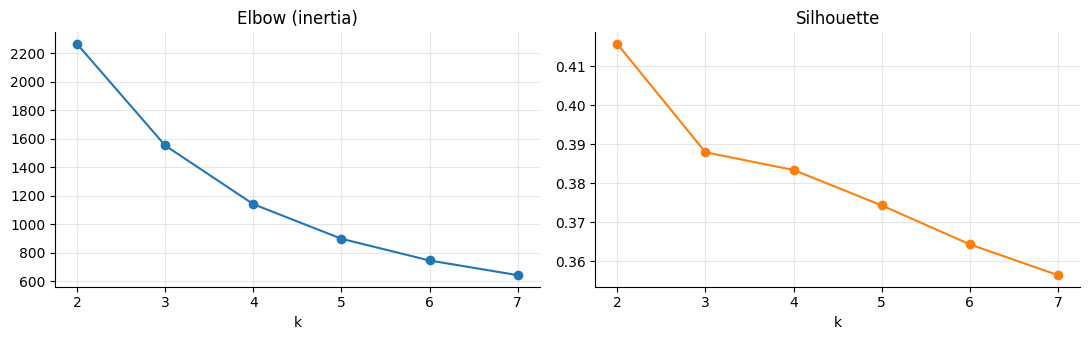

,k,inertia,silhouette
0,2,2264.067,0.416
1,3,1552.356,0.388
2,4,1141.457,0.383
3,5,898.904,0.374
4,6,746.698,0.364
5,7,643.974,0.356


In [3]:
ks = evaluate_k(rfm)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(ks.k, ks.inertia, "o-"); ax[0].set(title="Elbow (inertia)", xlabel="k")
ax[1].plot(ks.k, ks.silhouette, "o-", color="C1"); ax[1].set(title="Silhouette", xlabel="k")
plt.tight_layout(); plt.show(); ks.round(3)

We use **k = 4**: silhouette is still healthy and four personas (Champions / Loyal / At Risk / Hibernating) map to distinct marketing actions.

In [4]:
bundle = fit_segmentation(rfm, k=4)
seg = predict_segments(bundle, rfm)
print("silhouette:", round(bundle["silhouette"], 3))
segment_summary(seg)

silhouette: 0.383


,segment,customers,avg_recency_days,avg_frequency,avg_monetary,total_revenue,revenue_share_pct
0,Champions,430,18.2,77.3,9851.4,4236119.0,61.5
1,At Risk,459,255.5,27.5,3461.4,1588762.2,23.1
2,Loyal Customers,353,14.3,21.5,2714.9,958359.1,13.9
3,Hibernating,213,267.6,4.1,467.9,99673.3,1.4


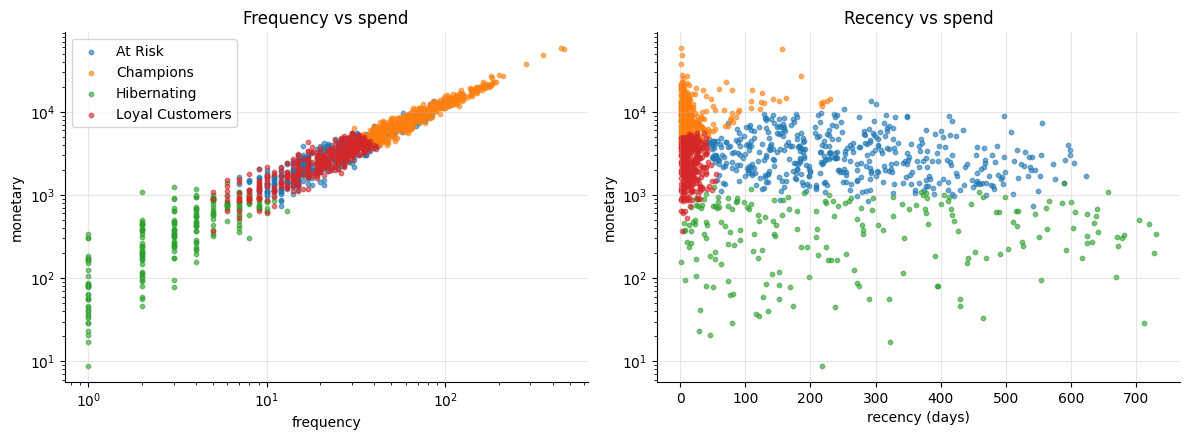

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for name, g in seg.groupby("segment"):
    ax[0].scatter(g.frequency, g.monetary, s=10, alpha=.6, label=name)
    ax[1].scatter(g.recency, g.monetary, s=10, alpha=.6, label=name)
ax[0].set(xscale="log", yscale="log", xlabel="frequency", ylabel="monetary", title="Frequency vs spend")
ax[1].set(yscale="log", xlabel="recency (days)", ylabel="monetary", title="Recency vs spend")
ax[0].legend(); plt.tight_layout(); plt.show()

## 3. Business interpretation
- **Champions** - few customers, majority of revenue → protect and reward.
- **Loyal Customers** - recent buyers with growth headroom → cross-sell.
- **At Risk** - once valuable but silent for ~8 months → win-back campaigns (feeds the churn model).
- **Hibernating** - low value and inactive → cheap reactivation only.

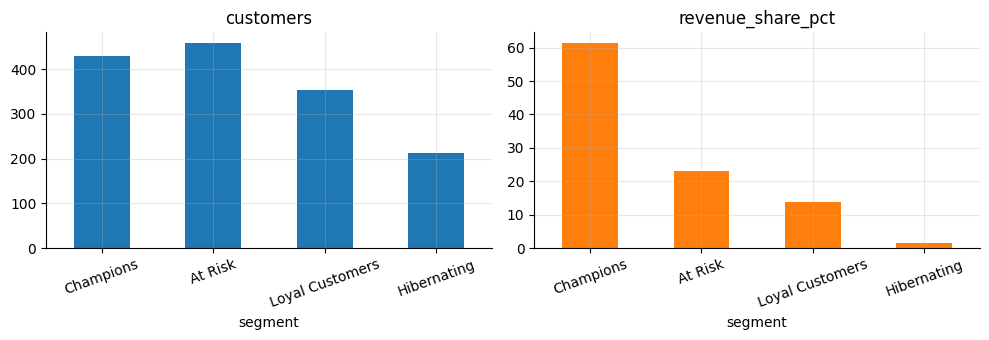

In [6]:
s = segment_summary(seg).set_index("segment")
s[["customers", "revenue_share_pct"]].plot.bar(subplots=True, layout=(1, 2), figsize=(10, 3.5), legend=False, rot=20); plt.tight_layout(); plt.show()